# Deep Active Subspace Coarse-Grained force-field UQ

Notebook to reproduce the DAS results of:

Maxime Vassaux, Xinju Dong, Shunzhou Wan, Wouter Edeling, Yiming Yang, Antigoni Georgiadou, Peter Coveney, *Reliabilty of coarse-grained molecular dynamics simulation of biomolecules using large-scale aleatoric and parametric uncertainty quantification*, 2026 (submitted).

**References**

[1] Edeling, W. (2023). On the deep active-subspace method. SIAM/ASA Journal on Uncertainty Quantification, 11(1), 62-90.

Import packages. Missing packages are installed by uncommenting the corresponding line below:

In [1]:
# !pip install numpy
# !pip install matplotlib
# !pip install scipy
# !pip install tqdm
# !pip install torch

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg, stats
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset
from torch.utils.data import random_split

In [3]:
# set figure resolution
plt.rcParams['savefig.dpi'] = 300

In [4]:
# fix random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

### Pick a QoI



In [5]:
QoI = 'local_twist_average'
# QoI = 'persistence_length'

### Load input parameter values and output

Let ${\bf x}\in\mathbb{R}^{D}$ denote the high-dimensional vector of uncertain input (force-field) parameters, with joint probability density $p({\bf x})=\prod_{i=1}^D p(x_i)$, such that ${\bf x}\sim p({\bf x})$. A (scalar) quantity of interest produced by the CG MD model is denoted by $f({\bf x})\in\mathbb{R}$. We will average $f({\bf x})$ over the available replicas. 

In [6]:
# data = np.load(f'./data/data_{QoI}_err_only.npz')
data = np.load(f'./data/data_{QoI}_err_only_replicas.npz')
x = data['X']
chain = 0
f = data['Y'][:,chain].reshape([-1, 1])
param_names = data['param_keys']
# remove "err_" from all the parameter names
param_names = np.array([name[4:] for name in param_names])
#run_ids = data['run_ids']

In [7]:
if QoI == 'persistence_length':
    # samples with a persistence length < 100 are discarded
    idx = np.where(f >= 100)[0]
    f = f[idx]
    x = x[idx]

### Average over the replicas

To remove the noise from the data, we average over the replica simulations

In [8]:
# Get unique rows, first occurrence indices, and counts
unique_x, indices, counts = np.unique(x, axis=0, return_index=True, return_counts=True)

# Get the sorting order to restore original sequence
sort_order = np.argsort(indices)

# Apply the order to both rows and counts
unique_x = unique_x[sort_order]
counts = counts[sort_order]

# number of unique parameter values
n_unique_samples = unique_x.shape[0]

# all samples
samples_per_param = {}

# samples averaged over replicas
mean_samples = np.zeros([n_unique_samples, 1])

start = 0
for i, c in enumerate(counts):
    samples_per_param[i] = f[start:start+c]
    mean_samples[i] = np.mean(samples_per_param[i])
    start = start + c

Plot the sorted replica mean and the replica spread around the mean

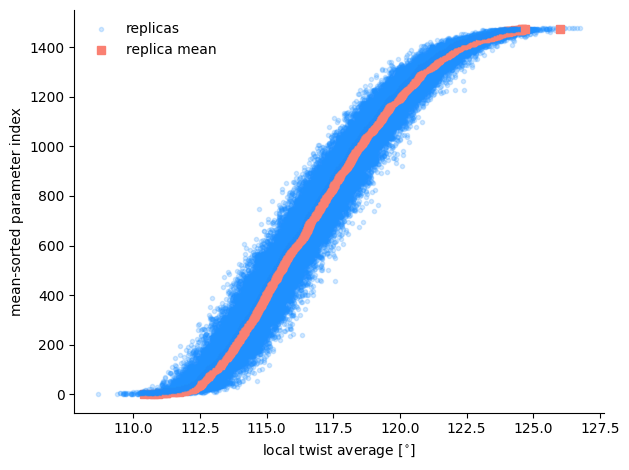

In [9]:
idx = np.argsort(mean_samples.flatten())

lbl = {'local_twist_average': 'local twist average [%s]' % (r'${}^{\circ}$',), 
       'persistence_length': r'persistence length [%s]' % (r'$\mathring{A}$')}

fig = plt.figure(f'samples_{QoI}')
ax = fig.add_subplot(111)
for i in range(len(samples_per_param)):
    s = samples_per_param[idx[i]]
    ax.plot(s, np.ones(s.size) * i + 1, '.', color = 'dodgerblue', alpha = 0.2, label='replicas')
    ax.plot(mean_samples[idx[i]], i, 's', color='salmon', label='replica mean')

ax.set_xlabel(lbl[QoI])
ax.set_ylabel('mean-sorted parameter index')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# remove duplicate legends
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), draggable=True, frameon=False)

plt.savefig(f'./images/samples_{QoI}.png', dpi = 300)
plt.tight_layout()

Here we set the $({\bf x}_i, f({\bf x}))$, $i=1,\cdots,N$ training data to be the unique force-field parameter values as input features, with replica-averaged CG MD outputs as target.

In [10]:
# inputs
x = torch.Tensor(unique_x)
# outputs
f = torch.Tensor(mean_samples)

In [11]:
# number of samples
N = x.shape[0]

# number of inputs
D = x.shape[1]

print(f"There are {D} input paramaters")
print(f"There are {N} samples")

# scale inputs within [-1, 1]
x_max = x.max(axis=0)[0]
x_min = x.min(axis=0)[0]
x = (x - 0.5 * (x_min + x_max)) / (0.5 * (x_max - x_min))

# standardize the output
f_mean = f.mean()
f_std = f.std()
f = (f - f_mean) / f_std

There are 620 input paramaters
There are 1476 samples


###  Define DAS architecture

As discussed in the article, we opt for the simplified DAS architecture, with a $d$-dimensional bottleneck but an unconstrained (nonlinear) encoder. An orthonormal basis for the learned subspace will be extracted in a post-processing step. This is in contrast to the DAS network of [1], where orthonomality of the DAS layer is hard-coded into the architecture.

In [12]:
class Net(nn.Module):
    def __init__(self, n_neurons):
        super().__init__()
        self.net = nn.Sequential(
            # DAS layer
            nn.Linear(D, d),
            nn.Tanh(),
            nn.Linear(d, n_neurons),
            nn.Tanh(),
            nn.Linear(n_neurons, n_neurons),
            nn.Tanh(),
            nn.Linear(n_neurons, 1)
        )

    def forward(self, x):
        return self.net(x)

### Training / validation split of the data

In [13]:
# test fraction
test_frac = 0.1
# indices of the validation set
val_idx = int((1 - test_frac) * N)
# training set
x_train = x[0:val_idx, :]
f_train = f[0:val_idx, :]
# validation set
x_val = x[val_idx:, :]
f_val = f[val_idx:, :]

### Selecting $d$

Here we execute the 1D grid search for selecting the subspace dimension $d$. The results are already stored to disk. If you want to repeat the training set `train = True`.

In [14]:
models = {}
train_loss = {}
val_loss = {}

# number of neurons in the hidden layer
n_neurons = 50
# number of replica networks to train
n_replica = 10
# maximum subspace dimension to be considered
d_max = 5

In [15]:
train = False
if train:
    # loop over subspace dimensions
    for d in tqdm(range(1, d_max + 1)):
        models[d] = []
        train_loss[d] = []
        val_loss[d] = []

        # train replica network
        for n in range(n_replica):
            model = DAS(n_neurons)
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
            for i in range(10000):
                pred = model(x_train)
                loss = (0.5*(pred - f_train)**2).mean()
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            # store trained models
            models[d].append(model)

            with torch.no_grad():
                # compute relative errors
                train_loss[d].append(((model(x_train) - f_train) ** 2).sum() / (f_train ** 2).sum())    
                val_loss[d].append(((model(x_val) - f_val) ** 2).sum() / (f_val ** 2).sum())  
                print('=================================')
                print(f'Model {n + 1}, d = {d}: training error = {train_loss[d][-1]:.3f}, \
                validation error = {val_loss[d][-1]:.3f}')

    data = {'models': models, 'train_loss': train_loss, 'val_loss': val_loss}
    torch.save(data, f'./data/rel_errors_{QoI}.pt')
else:
    print(f'Loading training/validation errors and models from ./data/rel_errors_{QoI}.pt')
    data = torch.load(f'./data/rel_errors_{QoI}.pt', weights_only=False)
    models = data['models']
    train_loss = data['train_loss']
    val_loss = data['val_loss']

Loading training/validation errors and models from ./data/rel_errors_local_twist_average.pt


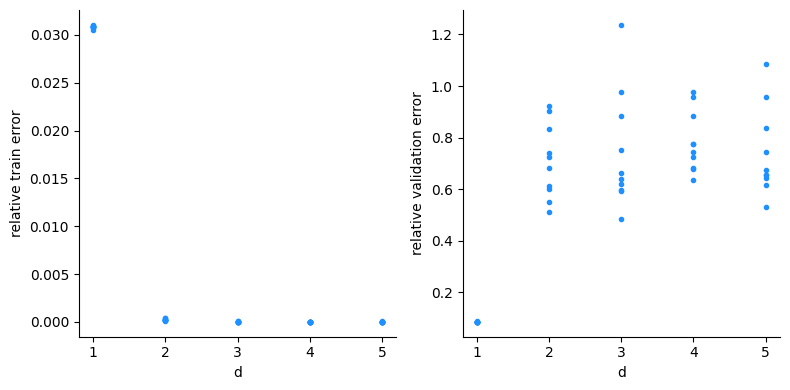

In [16]:
# plot the relative training and validation errors
with torch.no_grad():
    fig = plt.figure(figsize=[8, 4])
    ax = fig.add_subplot(121, yscale='linear')
    for d in range(1, d_max + 1):
        ax.plot(np.ones(n_replica) * d, train_loss[d], '.', color = 'dodgerblue')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel('d')
    ax.set_ylabel('relative train error')
    ax.set_xticks(np.arange(1, d_max + 1))
    #
    ax = fig.add_subplot(122, yscale='linear')
    for d in range(1, d_max + 1):
        ax.plot(np.ones(n_replica) * d, val_loss[d], '.', color = 'dodgerblue')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlabel('d')
    ax.set_ylabel('relative validation error')
    ax.set_xticks(np.arange(1, d_max + 1))
    plt.tight_layout()
    #
    fig.savefig(f'./images/errors_{QoI}.png')  

Based on the result above, we use $d=1$ for both QoI. 

In [17]:
d = 1
idx_min = np.argmin(val_loss[d])
# use the model with the lowest validation error
model = models[d][idx_min]
print(f'The minimim validation error for d = {d} is {data['val_loss'][d][idx_min]:.3f}')

The minimim validation error for d = 1 is 0.086


### Verification gradients

Below we perform a finite-difference verification of the gradient $\nabla\tilde{f}$.

In [18]:
def FD_check(model, x):
    """
    Finite difference check on the gradient computation
    """

    x = x.detach().clone().requires_grad_(True)
    model.zero_grad()
    # forward pass (scalar output)
    f0 = model(x)
    # compute gradient df/dx
    dfdx = torch.autograd.grad(f0, x, create_graph=True)[0]
    dfdx = dfdx.unsqueeze(dim=1)

    eps = 1e-3
    dfdx_fd = torch.zeros([x.shape[0]])
    for n in range(x.shape[0]):
        x_i = x.clone()
        x_i[n]  += eps
        f1 = model(x_i).detach()
        dfdx_fd[n] = (f1 - f0) / eps

    return dfdx, dfdx_fd        

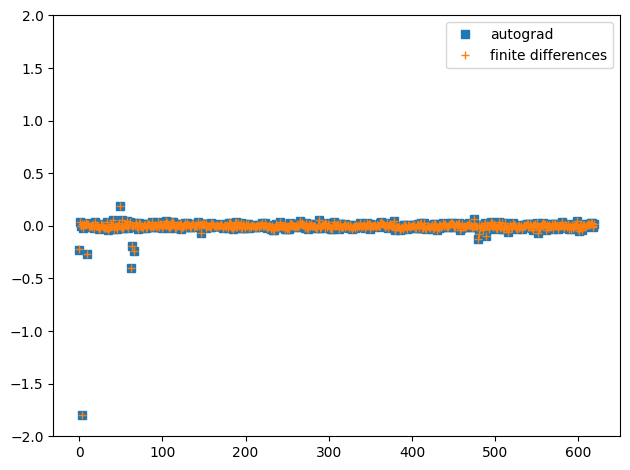

In [19]:
dfdx, dfdx_fd = FD_check(model, x_train[0])
with torch.no_grad():
    fig = plt.figure()
    ax = fig.add_subplot(111, ylim=[-2,2])
    ax.plot(dfdx, 's', label='autograd')
    ax.plot(dfdx_fd, '+', label='finite differences')
    plt.legend()
    plt.tight_layout()

### Compute $C_{DAS}$

In the current manuscript we compute:

\begin{align}
    C_{DAS} := \int \left(\nabla \tilde{f}\left({\bf x}\right)\right)\left(\nabla \tilde{f}\left({\bf x}\right)\right)^T p(\bf x)d{\bf x},
\end{align}

and extract the $d$ dominant eigenvectors in a post processing step. To differentiate from the weight matrix (which is not orthonormal in this architecture), we denote these eigenvectors by $U_1$, and write ${\bf y} = U_1^T{\bf x}$ for the active subspace. 

In [20]:
def compute_C(model, x):
    """
    model : Net
        PyTorch model
    x     : tensor
        The independent x variable
    """

    C = torch.zeros(D, D)

    for n in tqdm(range(x.shape[0])):
        model.zero_grad()
        x_n = x[n].detach().clone().requires_grad_(True)

        # forward pass (scalar output)
        f_n = model(x_n)

        # compute gradient df/dx
        dfdx = torch.autograd.grad(f_n, x_n, create_graph=True)[0]
        dfdx = dfdx.unsqueeze(dim=1)
        
        # accumulate C
        C += (dfdx @ dfdx.T) / N

    return C

In [21]:
C = compute_C(model, x_train)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1328/1328 [00:00<00:00, 1766.58it/s]


Compute the eigendecomposition of $C_{DAS}$. Note, if the network has $d$ neurons in the DAS layer, it will have at most $d$ non zero eigenvalues (see [1]). Any eigenvalues beyond this will be numerically zero.

In [22]:
# compute eigenvalues / vectors and flip order (from low --> high to high --> low)
eigvals_C, eigvecs_C = torch.linalg.eigh(C)
eigvals_C = eigvals_C.flip(0)
eigvecs_C = eigvecs_C.flip(1)

Plot the eigen values

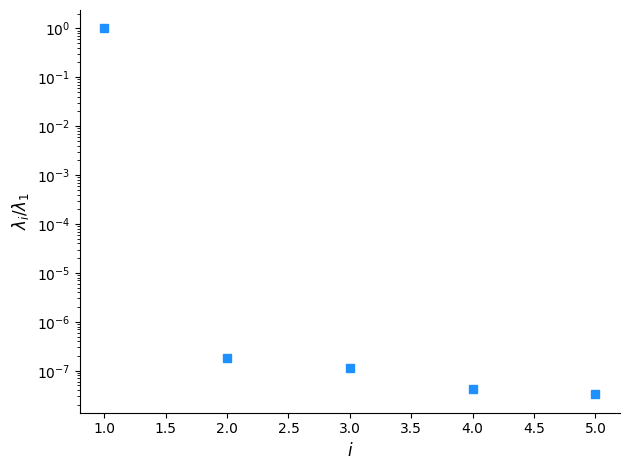

In [23]:
with torch.no_grad():
    n_plot = 5
    fig = plt.figure()
    ax = fig.add_subplot(111, yscale='log')
    ax.plot(np.arange(1, n_plot+1), eigvals_C[0:n_plot] / eigvals_C[0], 's', color='dodgerblue')
    ax.set_xlabel(r'$i$', fontsize=12)
    ax.set_ylabel(r'$\lambda_i / \lambda_1$', fontsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    fig.savefig(f'./images/eigvals_{QoI}_d{d}.png')

Create the projection matrix $U_1$, and compute active subspace coordinates

In [24]:
U_1 = eigvecs_C[:, 0:d]
y_train = (U_1.T @ x_train.T).T.detach()
y_val = (U_1.T @ x_val.T).T.detach()

Plot the surrogate and the data in the active subspace

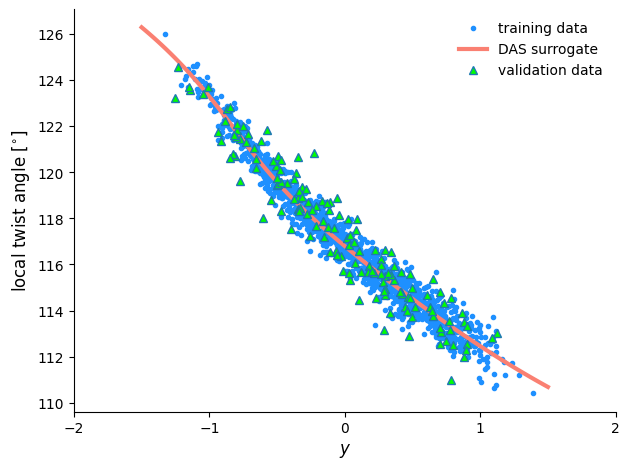

In [25]:
# QoI labels
lbl = {'local_twist_average': 'local twist angle [%s]' % (r'${}^{\circ}$',), 'persistence_length': r'persistence length'}

y_lin = torch.linspace(-1.5, 1.5, 100).unsqueeze(1)
x_lin = U_1 @ y_lin.T

with torch.no_grad():
    # plot DAS surrogate vs 1D active subspace
    fig = plt.figure() 
    ax = fig.add_subplot(111,  xlim=[-2,2])   
    ax.set_xlabel(r'$y$', fontsize=12)
    ax.set_xticks([-2, -1, 0, 1, 2])
    ax.set_ylabel(lbl[QoI], fontsize=12)
    ax.plot(y_train[:, 0], f_train * f_std + f_mean, '.', color='dodgerblue', label='training data') 
    ax.plot(y_lin, model(x_lin.T) * f_std + f_mean, color='salmon', label='DAS surrogate', linewidth=3)
    ax.plot(y_val[:, 0], f_val* f_std + f_mean, '^', markerfacecolor='lime', label='validation data', linewidth=3)
    leg = ax.legend(loc=0, frameon=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(f'./images/surrogate_{QoI}_chain{chain}_d{d}.png', dpi=300)                

### Activity scores

In many uncertainty quantification approaches, sensitivity indices that measure the importance of (sets of) parameters can be obtained cheaply once the sampling has been conducted. In the DAS case, these take the form of global derivative-based sensitivity indices, also called `activity scores'[1]:

\begin{align}
\nu_i :=\int\left(\frac{\partial f}{\partial x_i}\right)^2p\left({\bf x}\right)\mathrm{d}{\bf x}, \quad i = 1,\cdots, D.
\end{align}

These first-order indices measure the (average) sensitivity of $f$ to small perturbations in individual inputs $x_i$, and are especially suited for identifying non-influential parameters \cite{SOBOL20093009}. Note that the $\nu_i$ indices are the diagonal elements of the matrix $C$, such that these are indeed available through the a Monte Carlo estimate of $C$, or in the case of a neural network, of $C_{DAS}$. 

In [26]:
def plot_sensitivity(V_i, param_names, n_include = 25, height=0.4, **kwargs):
    """
    Plot the global derivative-based sensitivity indices with confidenceintervals

    Parameters
    ----------
    results : dict
        dict containing the results for each of the n_rep replica networks
    n_include : int, optional
        How many indices to plot. The default is 25.

    Returns
    -------
    None.

    """     
    idx = np.fliplr(np.argsort(np.abs(V_i.reshape([-1, 1])).T))[0]

    # plot results
    fig = plt.figure(figsize=[5, 10])
    ax = fig.add_subplot(111, title=kwargs.get('title', ''))

    offset = 0
    # if 'bar2' in kwargs:
    #     offset = height
    #     bar2 = kwargs['bar2'][param_names[idx]].values.flatten()
    #     bar2 /= bar2[0]
    #     ax.barh(np.array(range(n_include))-offset/2, width = bar2[0:n_include],
    #             color = 'salmon', height=height, label='KAS-GP', hatch='//')

    ax.set_xlabel(r'$\nu_i\;/\;\nu_1$', fontsize=18)
    nu_i = V_i[idx].flatten()
    nu_i /= nu_i[0]
    ax.barh(np.array(range(n_include))+offset/2, width = nu_i[0:n_include],
            color = 'dodgerblue', height=height, label='DAS')#, xerr = x_err[:, 0:n_include])
    ax.set_xticks(np.linspace(0, 1, 5))
    ax.set_yticks(range(n_include))
    ax.set_yticklabels(param_names[idx][0:n_include], fontsize=18)
    ax.invert_yaxis()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # plt.legend(loc=0, fontsize=18)
    plt.tight_layout()
    plt.savefig(f'./images/SA_{QoI}.pdf')

Compute the $\nu_i$ and plot the 25 largest values

In [27]:
V_i = (eigvals_C[0:d] * U_1 ** 2).sum(axis=1).detach().numpy()

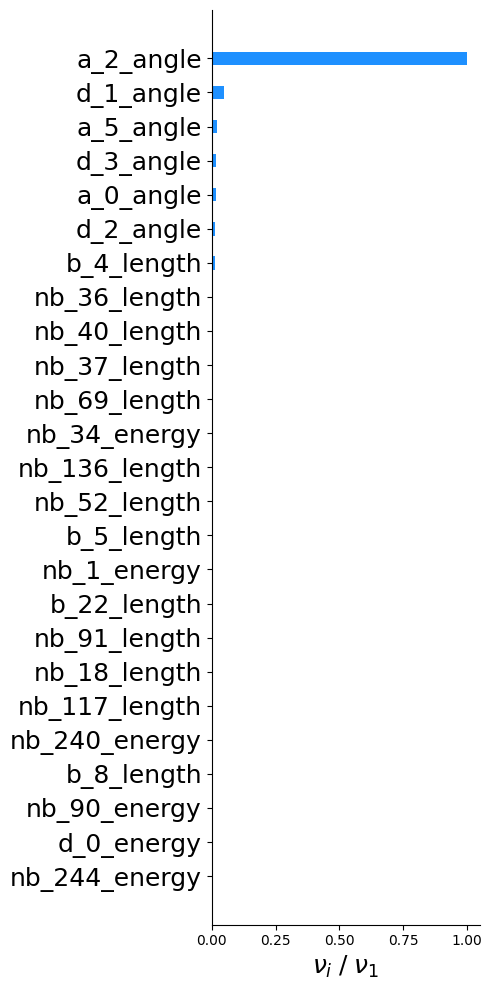

In [28]:
plot_sensitivity(V_i, param_names)